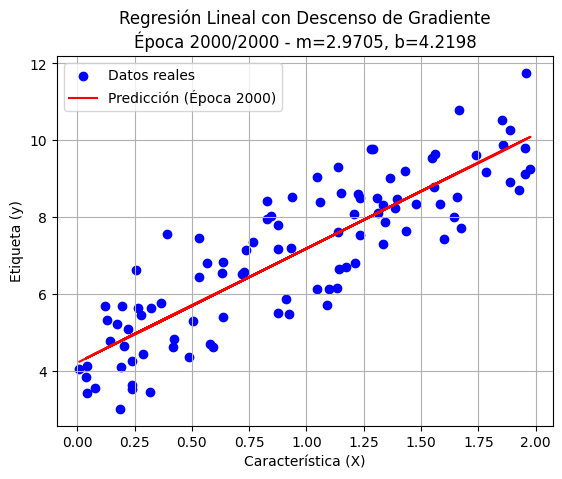


Entrenamiento completado después de 2000 épocas.
Parámetros óptimos encontrados: m = 2.9705, b = 4.2198
Valores reales usados para generar los datos: m_real = 3, b_real = 4


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import time
from IPython.display import clear_output

# --- 1. Generación de datos de ejemplo ---
# Generamos datos sintéticos con un patrón lineal y algo de ruido.
np.random.seed(0) # Para reproducibilidad
X = 2 * np.random.rand(100, 1) # 100 puntos entre 0 y 2
y = 4 + 3 * X + np.random.randn(100, 1) # y = 4 + 3x + ruido gaussiano

# --- 2. Inicialización de parámetros del modelo ---
# m = pendiente, b = intercepto
m = np.random.randn(1) # Inicializamos m aleatoriamente
b = np.random.randn(1) # Inicializamos b aleatoriamente

# Hiperparámetros del algoritmo de descenso de gradiente
learning_rate = 0.01 # Tasa de aprendizaje: controla el tamaño de los pasos
n_epochs = 1000 # Número de épocas: cuántas veces iterar sobre todo el conjunto de datos

# --- 3. Descenso de Gradiente ---
print(f"Parámetros iniciales: m = {m[0]:.4f}, b = {b[0]:.4f}\n")

plt.figure(figsize=(10, 6))

for epoch in range(n_epochs):
    # Predicciones actuales del modelo
    y_pred = m * X + b

    # Calculamos el error (diferencia entre el valor real y la predicción)
    error = y_pred - y

    # Calculamos los gradientes de la función de costo con respecto a m y b
    # La función de costo es MSE = (1/N) * sum((y_pred - y)^2)
    # Gradiente de MSE con respecto a m: (2/N) * sum(error * X)
    # Gradiente de MSE con respecto a b: (2/N) * sum(error)
    gradient_m = (2/len(X)) * np.sum(error * X)
    gradient_b = (2/len(X)) * np.sum(error)

    # Actualizamos los parámetros m y b usando la tasa de aprendizaje y los gradientes
    m = m - learning_rate * gradient_m
    b = b - learning_rate * gradient_b

    # --- 4. Visualización de datos y predicción del modelo (por época) ---
    if (epoch + 1) % 5 == 0 or epoch == 0 or epoch == n_epochs - 1: # Actualizamos el gráfico cada 5 épocas o al principio/fin
        clear_output(wait=True) # Borra la salida anterior para animar el gráfico
        plt.clf() # Limpia la figura actual

        # Graficar los puntos de datos originales
        plt.scatter(X, y, color='blue', label='Datos reales')

        # Graficar la línea de regresión actual
        plt.plot(X, m * X + b, color='red', label=f'Predicción (Época {epoch+1})')

        plt.title(f'Regresión Lineal con Descenso de Gradiente\nÉpoca {epoch+1}/{n_epochs} - m={m[0]:.4f}, b={b[0]:.4f}')
        plt.xlabel('Característica (X)')
        plt.ylabel('Etiqueta (y)')
        plt.legend()
        plt.grid(True)
        plt.show()
        # time.sleep(0.1) # Pequeña pausa para ver la actualización (opcional)


# --- 5. Resultados finales ---
print(f"\nEntrenamiento completado después de {n_epochs} épocas.")
print(f"Parámetros óptimos encontrados: m = {m[0]:.4f}, b = {b[0]:.4f}")
print("Valores reales usados para generar los datos: m_real = 3, b_real = 4")

# Puedes usar el modelo entrenado para hacer predicciones en nuevos datos
# X_nuevo = np.array([[2.5]])
# y_predicho = m * X_nuevo + b
# print(f"Predicción para X_nuevo = {X_nuevo[0][0]}: y = {y_predicho[0][0]:.4f}")


# Práctica Dirigida: Regresión Lineal y Evaluación del Modelo

**Asignatura:** Aprendizaje Automático / Machine Learning  
**Tema:** Regresión Lineal Simple y Evaluación con Datos de Prueba (*Testing Set*)  
**Duración estimada:** 45 – 60 minutos  

---

## 1. Objetivos de Aprendizaje
* **Entrenar** un modelo de regresión lineal simple ($f_{w,b}(x) = w \cdot x + b$) ajustando sus parámetros de peso ($w$) y sesgo ($b$).
* **Generar predicciones** sobre un conjunto de datos no visto durante el entrenamiento (*Testing Set*).
* **Evaluar** la precisión del modelo calculando el Error Cuadrático Medio ($\text{MSE}_{test}$) en la fase de prueba.

---

## 2. Contexto del Problema
Un equipo docente desea construir un modelo predictivo para estimar la **nota final de un examen** ($y$, en escala de 0.0 a 10.0) en función de las **horas de estudio semanales** ($x$) dedicadas por cada estudiante.

---

## 3. Conjuntos de Datos

### Tabla A: Conjunto de Entrenamiento (*Training Set*)
Utiliza estos 6 datos para ajustar los parámetros $w$ y $b$ de la función de hipótesis:

| Estudiante | Horas de estudio ($x$) | Nota obtenida ($y$) |
| :---: | :---: | :---: |
| 1 | 1.0 | 3.5 |
| 2 | 2.0 | 5.0 |
| 3 | 3.0 | 6.5 |
| 4 | 4.0 | 8.0 |
| 5 | 5.0 | 9.5 |
| 6 | 2.0 | 5.2 |

### Tabla B: Conjunto de Prueba (*Testing Set*)
Reserva estos 3 datos exclusivamente para la evaluación del modelo (no los uses durante el entrenamiento):

| Estudiante | Horas de estudio ($x_{test}$) | Nota real ($y_{real}$) |
| :---: | :---: | :---: |
| A | 1.5 | 4.25 |
| B | 3.5 | 7.25 |
| C | 4.5 | 8.75 |

---

## 4. Instrucciones Paso a Paso

### Parte 1: Entrenamiento del Modelo
1. Determina los parámetros del modelo de regresión lineal $f_{w,b}(x) = w \cdot x + b$ ajustando la recta a los datos de la **Tabla A**.
   * *Valores óptimos de referencia:* $w \approx 1.5$ y $b \approx 2.0$.

### Parte 2: Predicción sobre el Conjunto de Prueba
2. Sustituye las horas de estudio ($x_{test}$) de la **Tabla B** en la ecuación del modelo ajustado ($\hat{y} = w \cdot x_{test} + b$) para calcular la nota predicha ($\hat{y}$) para los estudiantes A, B y C.

### Parte 3: Evaluación del Error ($\text{MSE}_{test}$)
3. Calcula el error de predicción para cada estudiante del conjunto de prueba: $e^{(i)} = \hat{y}^{(i)} - y_{real}^{(i)}$.
4. Eleva cada error al cuadrado y calcula el promedio para obtener el Error Cuadrático Medio en prueba:

$$\text{MSE}_{test} = \frac{1}{3} \sum_{i=1}^{3} (\hat{y}^{(i)} - y_{real}^{(i)})^2$$

